# 11 · De la evidencia a la decisión: prueba controlada y memo al comité

**Pregunta de decisión.** ¿Cómo se prueba un cambio de política antes de generalizarlo, y qué se lleva al comité?

Los notebooks 07–10 producen estimaciones con supuestos: estabilidad del puente, tendencias paralelas, efectos locales, extrapolación de rechazados. Una política nueva se adopta cuando una **prueba controlada** confirma el efecto con la potencia necesaria, o cuando el costo de equivocarse es menor que el de esperar. Este notebook:

1. dimensiona dos pruebas: restringir el avance temprano en Experian y aprobar una muestra del swap-in de la alternativa B;
2. fija la regla de asignación auditable y revisa el balance;
3. arma el **memo de una página**: hallazgo, evidencia, efecto con IC, impacto anual y decisión propuesta.

> **Estado:** plantilla con demostración aislada simulada. Las cifras del memo son de la simulación y sirven para mostrar el formato y el razonamiento.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
BASE = Path.cwd()
if not (BASE / 'decision_core.py').exists():
    root = next(p for p in [BASE, *BASE.parents] if (p / '03-financial-risk').is_dir())
    BASE = root / '03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab'
sys.path.insert(0, str(BASE))
import decision_core as dc
from vintage_core import build_vintage, summarize_vintage
from demo_inputs import demo_cartera
plt.rcParams.update({'figure.figsize': (10, 4.6), 'font.size': 10.5, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18,
                     'axes.axisbelow': True, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
AZUL, OCRE, GRIS, ROJO = '#25658c', '#d4854a', '#9aa5b1', '#b5443b'
SIM = 'Datos simulados · no representa una cartera'
pd.options.display.float_format = '{:,.4f}'.format

def leer(nombre):
    """Lee una plantilla local; las del repositorio solo tienen encabezados."""
    return pd.read_csv(BASE / nombre, encoding='utf-8-sig')

def pct(x, d=1):
    return 'n/d' if pd.isna(x) else f'{100 * x:.{d}f} %'

def cop(x):
    return 'n/d' if pd.isna(x) else f'COP {x / 1e6:,.1f} M'

## 1 · Elementos del diseño

| Elemento | Contenido | Por qué importa |
|---|---|---|
| Hipótesis | efecto esperado y su origen (DiD, RD, inferencia) | fija el efecto mínimo que vale la pena detectar |
| Unidad y elegibles | cuenta o comercio; segmento afectado | define el efecto de diseño si se asigna por grupos |
| Brazos | champion (regla vigente) y challenger | un solo cambio por brazo para poder atribuirlo |
| Métrica primaria | EVER30 al MOB donde actúa el mecanismo | leer antes de que el efecto ocurra no prueba nada |
| Guardarraíles | aprobación, saldo, ingresos por comisión, quejas | evita ganar en mora y perder el negocio |
| Tamaño y duración | potencia 80 %, α 5 %, maduración | evita pruebas que terminan sin conclusión |
| Regla de detención | umbral de daño y lecturas intermedias | limita el costo de equivocarse |
| Asignación | hash determinista con sal propia | reproducible y auditable sin guardar tablas |

Tamaño por brazo para dos proporciones, con $\bar p=(p_0+r p_1)/(1+r)$:

$$n_0=\frac{\left(z_{1-\alpha/2}\sqrt{\bar p(1-\bar p)(1+1/r)}+z_{1-\beta}\sqrt{p_0(1-p_0)+p_1(1-p_1)/r}\right)^2}{(p_0-p_1)^2}.$$

Si se asigna por comercio o por cohorte, multiplicar por el efecto de diseño $1+(m-1)\rho$.

### Con datos de la entidad

In [2]:
experimentos = leer('plantilla_experimentos.csv')
print(f'Experimentos registrados: {len(experimentos):,}')
if experimentos.empty:
    print('PENDIENTE: registrar hipótesis, brazos, métrica, MDE, tamaño, sal de asignación y regla de detención antes de iniciar.')

Experimentos registrados: 0
PENDIENTE: registrar hipótesis, brazos, métrica, MDE, tamaño, sal de asignación y regla de detención antes de iniciar.


### Demostración aislada

In [3]:
# Cartera ficticia con mecanismos plantados (ver demo_inputs.demo_cartera).
DEMO = demo_cartera()
V = DEMO['verdad']
cuentas, solicitudes, panel_demo, macro_demo = DEMO['cuentas'], DEMO['solicitudes'], DEMO['panel'], DEMO['macro']
cuentas['banda_score'] = pd.cut(cuentas.score_buro, [0, 620, 660, 700, 2000], right=False,
                                labels=['<620', '620–659', '660–699', '700+'])
print(f'Solicitudes simuladas: {len(solicitudes):,} | aprobadas: {len(cuentas):,} | '
      f'EVER30@MOB3 simulado: {pct(cuentas.evento_temprano.mean())}')

Solicitudes simuladas: 30,000 | aprobadas: 20,379 | EVER30@MOB3 simulado: 10.5 %


In [4]:
# Insumos recalculados de los notebooks 07, 09 y 10 para que este notebook sea autocontenido.
c = cuentas.copy()
c['tpv'] = (c.estrategia_originacion == 'TPV').astype(int); c['post'] = (c.corte_origen >= '2024-07').astype(int)
c['avance_mob1'] = (c.primer_mob_avance.astype('float') == 1).astype(int)
did = dc.did_estimate(c, outcome_col='evento_temprano', treated_col='tpv', post_col='post', cluster_col='corte_origen')
fs = dc.did_estimate(c, outcome_col='avance_mob1', treated_col='tpv', post_col='post', cluster_col='corte_origen')
wald = did['efecto'] / fs['efecto']
puente = dc.bridge_to_loss(c).iloc[0]
cast = c[(c.seguimiento_largo_completo == 1) & (c.castigo_largo == 1)]
LGD = cast.perdida_neta_cop.sum() / cast.saldo_mob3.sum()
perdida_por_evento = puente.p_castigo_dado_evento * LGD * c.saldo_mob3.mean()
exp_ = c[c.estrategia_originacion == 'Experian']
p_exp = exp_.evento_temprano.mean()
tasa_av_tpv_pre = c[(c.tpv == 1) & (c.post == 0)].avance_mob1.mean()
reduccion_relativa = -fs['efecto'] / tasa_av_tpv_pre  # supuesto: en Experian la restricción reduce el avance en la misma proporción
fs_exp = exp_.avance_mob1.mean() * reduccion_relativa
efecto_esperado = wald * -fs_exp
print(f'EVER30@MOB3 Experian: {pct(p_exp)} | efecto por avance evitado (Wald): {100 * wald:.1f} pp | '
      f'reducción esperada de avance en MOB 1: {100 * fs_exp:.1f} pp | efecto esperado: {100 * efecto_esperado:+.2f} pp')

EVER30@MOB3 Experian: 11.2 % | efecto por avance evitado (Wald): 6.6 pp | reducción esperada de avance en MOB 1: 16.3 pp | efecto esperado: -1.07 pp


## 2 · Prueba A: restringir el avance temprano en Experian

**Hipótesis:** extender P-AV-02 a Experian reduce el EVER30@MOB3 en $\delta\approx \text{Wald}\times\Delta\text{avance}$. **Métrica:** el avance actúa desde MOB 2, así que una lectura en MOB 1 no prueba nada; la lectura temprana válida es la **primera etapa** (tasa de avance) en MOB 1, y la primaria es el EVER30 en MOB 3.

,efecto_supuesto_pp,proporcion_challenger,n_control,n_challenger,meses_originacion,meses_hasta_lectura_mob3
0,-0.5342,0.2000,134569,33643,143.5282,146.5282
1,-0.5342,0.5000,53556,53556,91.3925,94.3925
2,-1.0684,0.2000,33089,8273,35.2944,38.2944
3,-1.0684,0.5000,13100,13100,22.3549,25.3549
4,-1.6027,0.2000,14457,3615,15.4224,18.4224
5,-1.6027,0.5000,5693,5693,9.7150,12.7150


Con 12 meses de originación Experian repartidos 50/50, el efecto mínimo detectable es 1.45 pp.


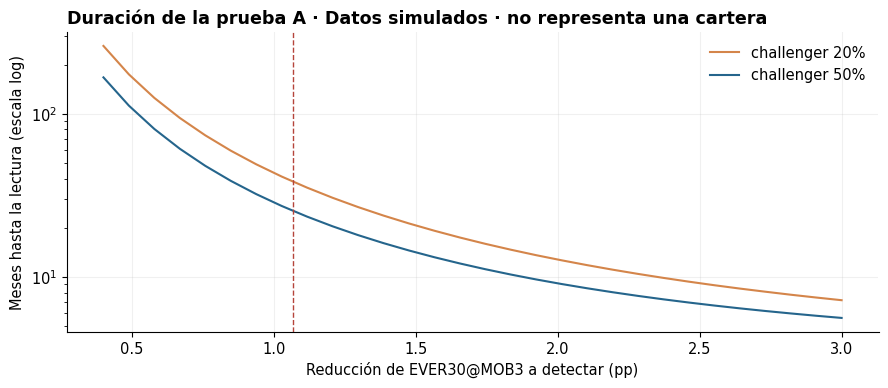

In [5]:
mensual = len(exp_) / 12
filas = []
for mult in (.5, 1, 1.5):
    d_ = efecto_esperado * mult
    for share in (.2, .5):
        n = dc.sample_size_two_proportions(p_exp, p_exp + d_, ratio=share / (1 - share))
        meses = max(n['n_control'] / ((1 - share) * mensual), n['n_challenger'] / (share * mensual))
        filas.append({'efecto_supuesto_pp': 100 * d_, 'proporcion_challenger': share, 'n_control': n['n_control'],
                      'n_challenger': n['n_challenger'], 'meses_originacion': meses, 'meses_hasta_lectura_mob3': meses + 3})
diseno = pd.DataFrame(filas); display(diseno)
base = diseno[(diseno.efecto_supuesto_pp.round(4) == round(100 * efecto_esperado, 4)) & (diseno.proporcion_challenger == .5)].iloc[0]
mde_anual = dc.mde_two_proportions(p_exp, int(mensual * 6), int(mensual * 6))
print(f'Con 12 meses de originación Experian repartidos 50/50, el efecto mínimo detectable es {100 * mde_anual:.2f} pp.')
fig, ax = plt.subplots(figsize=(9, 4))
efectos = np.linspace(.004, .03, 30)
for share, color in [(.2, OCRE), (.5, AZUL)]:
    meses = [max(dc.sample_size_two_proportions(p_exp, p_exp - e, ratio=share / (1 - share))['n_control'] / ((1 - share) * mensual),
                 dc.sample_size_two_proportions(p_exp, p_exp - e, ratio=share / (1 - share))['n_challenger'] / (share * mensual)) + 3
             for e in efectos]
    ax.plot(100 * efectos, meses, color=color, label=f'challenger {share:.0%}')
ax.axvline(100 * -efecto_esperado, color=ROJO, ls='--', lw=1); ax.set_yscale('log')
ax.set(xlabel='Reducción de EVER30@MOB3 a detectar (pp)', ylabel='Meses hasta la lectura (escala log)', title=f'Duración de la prueba A · {SIM}')
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 3 · Prueba B: aprobar una muestra del swap-in

**Hipótesis:** el swap-in de la alternativa B tiene una tasa de malos por debajo de la tasa de equilibrio. Aquí no se compara contra un control: se necesita **precisión** sobre una tasa. Con semiancho $h$ del IC 95 %: $n=z^2 p(1-p)/h^2$. La prueba tiene un **costo de información**: las cuentas aprobadas que resulten malas. Se aprueba la alternativa si el límite superior del IC queda por debajo de la tasa de equilibrio.

In [6]:
s = solicitudes.copy(); s['log_tpv'] = np.log(s.tpv_mensual_cop)
s['politica_b'] = np.where(s.estrategia_originacion == 'TPV', (s.score_buro >= 540) & (s.log_tpv >= 14.6), s.score_buro >= 620).astype(int)
tpv_s = s[s.estrategia_originacion == 'TPV']
pred, _ = dc.infer_rejects_model(tpv_s[tpv_s.aprobada == 1], tpv_s[tpv_s.aprobada == 0], features=['score_buro', 'log_tpv'],
                                 outcome_col='evento_interno_mob3')
s.loc[pred.index, 'malo_inferido'] = pred
swap_in = s[(s.aprobada == 0) & (s.politica_b == 1)]
p_in = swap_in.malo_inferido.mean()

# Economía con los supuestos ilustrativos del notebook 08.
SUP = dict(tasa=.27, intercambio=40_000, fondeo=.105, opex=110_000, adquisicion=180_000, H=3, tau=.75, cobranza=100_000)
margen = c.saldo_mob3 * (SUP['tasa'] - SUP['fondeo']) + SUP['intercambio'] - SUP['opex'] - SUP['adquisicion'] / SUP['H']
valor = dc.account_lifetime_value(c, bad_col='evento_temprano', balance_col='saldo_mob3', annual_margin=margen, horizon_years=SUP['H'],
                                  p_loss_bad=puente.p_castigo_dado_evento, p_loss_good=puente.p_castigo_sin_evento, lgd=LGD,
                                  years_to_loss=SUP['tau'], collection_cost_bad=SUP['cobranza'])
c['valor_vida'] = valor
tpv_c = c[c.estrategia_originacion == 'TPV']
equilibrio = dc.breakeven_bad_rate(tpv_c.valor_vida, tpv_c.evento_temprano)
g_bueno, l_malo = tpv_c.valor_vida[tpv_c.evento_temprano == 0].mean(), -tpv_c.valor_vida[tpv_c.evento_temprano == 1].mean()
filas = []
for h in (.04, .03, .02):
    n = int(np.ceil(1.96 ** 2 * p_in * (1 - p_in) / h ** 2))
    valor_prueba = n * ((1 - p_in) * g_bueno - p_in * l_malo)
    filas.append({'semiancho_ic_pp': 100 * h, 'n_aprobar': n, 'fraccion_del_swap_in': n / len(swap_in),
                  'malos_esperados': n * p_in, 'valor_esperado_prueba_cop': valor_prueba})
prueba_b = pd.DataFrame(filas); display(prueba_b)
print(f'Swap-in TPV: {len(swap_in):,} solicitudes | malos inferidos {pct(p_in)} | tasa de equilibrio TPV {pct(equilibrio)}')

,semiancho_ic_pp,n_aprobar,fraccion_del_swap_in,malos_esperados,valor_esperado_prueba_cop
0,4.0000,307,0.1636,46.1548,"21,280,184.8151"
1,3.0000,546,0.2909,82.0864,"37,846,843.3519"
2,2.0000,1227,0.6537,184.4688,"85,051,422.6975"


Swap-in TPV: 1,877 solicitudes | malos inferidos 15.0 % | tasa de equilibrio TPV 29.4 %


## 4 · Asignación auditable y balance

In [7]:
brazo = dc.assign_challenger(exp_.id_credito, share=.5, salt='EXP-AV-01')
e = exp_.assign(challenger=brazo.to_numpy())
def smd(x, t):
    a, b = x[t == 1].astype(float), x[t == 0].astype(float)
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
balance = pd.Series({'score_buro': smd(e.score_buro, e.challenger), 'saldo_mob3': smd(e.saldo_mob3, e.challenger),
                     'persona juridica': smd((e.tipo_persona == 'juridica').astype(int), e.challenger)}
                    | {f'depto {d}': smd((e.departamento == d).astype(int), e.challenger) for d in sorted(e.departamento.unique())},
                    name='diferencia estandarizada').to_frame()
display(balance)
print(f"Challenger: {e.challenger.mean():.1%} de {len(e):,} cuentas | la misma sal reproduce la asignación: "
      f"{dc.assign_challenger(exp_.id_credito, share=.5, salt='EXP-AV-01').equals(brazo)}")
assert balance.abs().max().iloc[0] < .05, 'Desbalance mayor a 0,05 DE: revisar la asignación'

,diferencia estandarizada
score_buro,-0.0410
saldo_mob3,-0.0184
persona juridica,-0.0231
depto Antioquia,0.0039
depto Atlántico,0.0080
depto Bogotá D.C.,-0.0252
depto Nariño,-0.0139
depto Santander,-0.0106
depto Valle del Cauca,0.0384


Challenger: 49.4% de 14,064 cuentas | la misma sal reproduce la asignación: True


## 5 · Memo al comité

Cada fila se calcula con la evidencia de los notebooks 07–10, recalculada aquí. El impacto anual usa la originación de los 12 meses simulados y la pérdida esperada por evento ($a\times LGD\times$ saldo medio).

In [8]:
# R1 · Cohorte fuera de banda
ref = c[c.corte_origen < '2024-07'].evento_temprano.mean()
coh = c.groupby('corte_origen').evento_temprano.agg(['mean', 'size'])
peor = coh['mean'].idxmax()
exceso = (coh.loc[peor, 'mean'] - ref) * coh.loc[peor, 'size'] * perdida_por_evento
# R2 · Restricción de avance
tpv_anual = (c.estrategia_originacion == 'TPV').sum()
ahorro_mora = -did['efecto'] * tpv_anual * perdida_por_evento
comision_perdida = -fs['efecto'] * tpv_anual * 60_000
# R3 · Alternativa B
ambas = s[(s.aprobada == 1) & (s.politica_b == 1)]
ever_a = s.loc[s.aprobada == 1, 'evento_interno_mob3'].mean()
ever_b = (ambas.evento_interno_mob3.sum() + swap_in.malo_inferido.sum()) / s.politica_b.sum()
eventos_evitados = ever_a * s.aprobada.sum() - ever_b * s.politica_b.sum()
# R4 · Corte de TPV
marginal = tpv_c[tpv_c.score_buro < tpv_c.score_buro.min() + 20].evento_temprano.mean()
# R5 · Cupo alto
rd = dc.rd_local_linear(c, running_col='score_buro', outcome_col='evento_temprano', cutoff=700, bandwidth=40)

memo = pd.DataFrame([
    {'#': 1, 'Hallazgo': f'La cohorte {peor} sale de banda en MOB 1–3', 'Evidencia': 'bandas con sobredispersión + hazard con macro (07)',
     'Efecto (IC)': f"{100 * (coh.loc[peor, 'mean'] - ref):+.1f} pp vs. referencia", 'Impacto anual': cop(exceso) + ' de pérdida adicional',
     'Decisión propuesta': 'revisar canales, mezcla y reglas vigentes ese mes', 'Siguiente paso': 'auditoría de originación de la cohorte'},
    {'#': 2, 'Hallazgo': 'El avance temprano anuncia y además causa mora', 'Evidencia': 'landmark exagera; DiD sobre P-AV-02 (10)',
     'Efecto (IC)': f"{100 * did['efecto']:+.2f} pp ({100 * did['ic_bajo']:+.2f} a {100 * did['ic_alto']:+.2f})",
     'Impacto anual': f'{cop(ahorro_mora)} menos pérdida, {cop(comision_perdida)} menos comisiones',
     'Decisión propuesta': ('P-AV-02 no se paga con estos supuestos: focalizarla en perfiles de mayor riesgo; usar el avance en MOB 1 como alerta'
                            if ahorro_mora < comision_perdida else 'mantener P-AV-02 en TPV; usar el avance en MOB 1 como alerta'),
     'Siguiente paso': f"prueba A general no rinde ({base.meses_hasta_lectura_mob3:.0f} meses hasta leer): diseñarla sobre el segmento focalizado"},
    {'#': 3, 'Hallazgo': 'La alternativa B reasigna aprobación hacia TPV con TPV alto', 'Evidencia': 'swap set + inferencia en aprobados (09)',
     'Efecto (IC)': f'EVER {pct(ever_a)} → {pct(ever_b)}; swap-in {pct(p_in)} inferido',
     'Impacto anual': f'{eventos_evitados:,.0f} eventos menos ≈ {cop(eventos_evitados * perdida_por_evento)}',
     'Decisión propuesta': ('lanzar la prueba B: su valor esperado es positivo' if prueba_b.iloc[-1].valor_esperado_prueba_cop > 0
                            else 'no adoptar sin evidencia directa del swap-in'),
     'Siguiente paso': f"prueba B: aprobar {prueba_b.iloc[-1].n_aprobar:,.0f} del swap-in (IC ±2 pp)"},
    {'#': 4, 'Hallazgo': 'El corte de TPV es conservador', 'Evidencia': 'tasa de malos de equilibrio (08)',
     'Efecto (IC)': f'banda marginal {pct(marginal)} vs. equilibrio {pct(equilibrio)}', 'Impacto anual': 'valor por aflojar: se cuantifica con la prueba B',
     'Decisión propuesta': 'no endurecer; evaluar aflojar con la prueba B', 'Siguiente paso': 'vigilar la banda marginal mensualmente'},
    {'#': 5, 'Hallazgo': 'El cupo alto en 700 eleva la mora temprana', 'Evidencia': 'RD en el umbral de cupo (10)',
     'Efecto (IC)': f"{100 * rd['salto']:+.2f} pp ({100 * rd['ic_bajo']:+.2f} a {100 * rd['ic_alto']:+.2f})",
     'Impacto anual': f"{cop(rd['salto'] * 1000 * perdida_por_evento)} por cada 1.000 cuentas en el umbral",
     'Decisión propuesta': 'evaluar cupo escalonado (aumento a MOB 3 si hay buen pago)', 'Siguiente paso': 'incluir como brazo en una prueba de cupo'},
])
def tabla_md(df):
    filas = ['| ' + ' | '.join(df.columns) + ' |', '|' + '---|' * len(df.columns)]
    filas += ['| ' + ' | '.join(str(v).replace('|', '/') for v in r) + ' |' for r in df.itertuples(index=False)]
    return '\n'.join(filas)
display(Markdown(tabla_md(memo)))
neto_av = ahorro_mora - comision_perdida
avance = (f"la restricción de avance, que reduce la mora, **resta** {cop(-neto_av)} netos al año si se aplica a todo TPV"
          if neto_av < 0 else f"la restricción de avance suma {cop(neto_av)} netos al año")
display(Markdown(f"**Lectura (simulada).** Las cinco filas responden a las seis preguntas del laboratorio. Las dos decisiones con más "
                 f"valor son contraintuitivas: {avance}; y el corte de TPV deja valor sin capturar, porque la banda marginal tiene "
                 f"{pct(marginal)} de malos con un equilibrio de {pct(equilibrio)}. La prueba B convierte esa holgura en evidencia "
                 f"con un valor esperado de {cop(prueba_b.iloc[-1].valor_esperado_prueba_cop)}."))

| # | Hallazgo | Evidencia | Efecto (IC) | Impacto anual | Decisión propuesta | Siguiente paso |
|---|---|---|---|---|---|---|
| 1 | La cohorte 2024-09 sale de banda en MOB 1–3 | bandas con sobredispersión + hazard con macro (07) | +4.9 pp vs. referencia | COP 30.7 M de pérdida adicional | revisar canales, mezcla y reglas vigentes ese mes | auditoría de originación de la cohorte |
| 2 | El avance temprano anuncia y además causa mora | landmark exagera; DiD sobre P-AV-02 (10) | -0.91 pp (-2.96 a +1.13) | COP 22.4 M menos pérdida, COP 52.7 M menos comisiones | P-AV-02 no se paga con estos supuestos: focalizarla en perfiles de mayor riesgo; usar el avance en MOB 1 como alerta | prueba A general no rinde (25 meses hasta leer): diseñarla sobre el segmento focalizado |
| 3 | La alternativa B reasigna aprobación hacia TPV con TPV alto | swap set + inferencia en aprobados (09) | EVER 10.5 % → 10.1 %; swap-in 15.0 % inferido | 95 eventos menos ≈ COP 36.7 M | lanzar la prueba B: su valor esperado es positivo | prueba B: aprobar 1,227 del swap-in (IC ±2 pp) |
| 4 | El corte de TPV es conservador | tasa de malos de equilibrio (08) | banda marginal 12.7 % vs. equilibrio 29.4 % | valor por aflojar: se cuantifica con la prueba B | no endurecer; evaluar aflojar con la prueba B | vigilar la banda marginal mensualmente |
| 5 | El cupo alto en 700 eleva la mora temprana | RD en el umbral de cupo (10) | +1.12 pp (-1.35 a +3.60) | COP 4.3 M por cada 1.000 cuentas en el umbral | evaluar cupo escalonado (aumento a MOB 3 si hay buen pago) | incluir como brazo en una prueba de cupo |

**Lectura (simulada).** Las cinco filas responden a las seis preguntas del laboratorio. Las dos decisiones con más valor son contraintuitivas: la restricción de avance, que reduce la mora, **resta** COP 30.3 M netos al año si se aplica a todo TPV; y el corte de TPV deja valor sin capturar, porque la banda marginal tiene 12.7 % de malos con un equilibrio de 29.4 %. La prueba B convierte esa holgura en evidencia con un valor esperado de COP 85.1 M.

## 6 · Seguimiento después de la decisión

| Indicador | Frecuencia | Disparador | Fuente |
|---|---|---|---|
| Cohorte frente a curva esperada (MOB 1, 2, 3) | mensual | fuera de banda dos meses seguidos | notebook 07 |
| PSI del score de solicitantes por estrategia | mensual | > 0,10 vigilar; > 0,25 revisar política | notebook 09 |
| Gini del score por cohorte madura | trimestral | caída > 5 puntos frente a la referencia | notebook 09 |
| Tasa de malos de la banda marginal frente a la de equilibrio | mensual | marginal > equilibrio | notebook 08 |
| Puente $a$, $b$ por cohorte madura | trimestral | fuera del IC del puente vigente | notebook 07 |
| Primera etapa y guardarraíles de cada prueba | mensual | daño mayor que el umbral de detención | este notebook |

**Límites.** El memo de la demostración resume una simulación. Con datos reales, cada cifra hereda los supuestos de su notebook: estabilidad del puente, tendencias paralelas, efecto local del RD y extrapolación de rechazados. El memo debe citarlos.